# Extended Data Figure 10

Panels b–g (open search of histone samples of PXD024745) drawn from the per-PSM files `Wilhelm_SourceData_ED_Fig10b.parquet` ... `Wilhelm_SourceData_ED_Fig10g.parquet` (one row per point); legend n and medians from `Wilhelm_SourceData_ED_Fig10b.csv` ... `Wilhelm_SourceData_ED_Fig10g.csv`. Panel a is a schematic. Spectral angle = normalised spectral angle between the experimental spectrum and the Prosit-22PTM prediction of the candidate (0-1); colour = legend group (`modification`); solid line = diagonal.

Data are loaded with `source_data.py` (same folder) from the figshare deposit: set `FIGSHARE_ARTICLE_ID` in the next cell (or the environment variable of the same name), or `SOURCE_DATA_DIR` to a local copy of the files; while the article is private, set `FIGSHARE_TOKEN`. Panels are saved to `regenerated_panels/ED_Fig10/`.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig10'
FIG_DIR.mkdir(parents=True, exist_ok=True)


pts = {p: pd.read_parquet(fetch(f"Wilhelm_SourceData_ED_Fig10{p}.parquet")) for p in "bcdefg"}
legend = {p: table(f"ED_Fig10{p}").set_index('modification') for p in "bcdefg"}
pd.set_option('display.max_colwidth', 200)
readme('ED_Fig10')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 10,b,NaN,Wilhelm_SourceData_ED_Fig10b.parquet; Wilhelm_SourceData_ED_Fig10c.parquet; Wilhelm_SourceData_ED_Fig10b.csv,"Spectral angle of each open-search PSM, acetylation vs guanidination; n and medians in Wilhelm_SourceData_ED_Fig10b.csv.",NaN
1,Extended Data Fig. 10,c,NaN,Wilhelm_SourceData_ED_Fig10b.parquet; Wilhelm_SourceData_ED_Fig10c.parquet; Wilhelm_SourceData_ED_Fig10c.csv,"Delta retention time of each PSM, acetylation vs guanidination; n and medians in Wilhelm_SourceData_ED_Fig10c.csv.",NaN
2,Extended Data Fig. 10,d,NaN,Wilhelm_SourceData_ED_Fig10d.parquet; Wilhelm_SourceData_ED_Fig10d.csv,"Spectral angle of each PSM, propionylation vs diethylation / trimethylation; n and medians in Wilhelm_SourceData_ED_Fig10d.csv.",NaN
3,Extended Data Fig. 10,e,NaN,Wilhelm_SourceData_ED_Fig10e.parquet; Wilhelm_SourceData_ED_Fig10f.parquet; Wilhelm_SourceData_ED_Fig10e.csv,"Spectral angle of each PSM, N-pyruvic acid vs propionate-methyl; n and medians in Wilhelm_SourceData_ED_Fig10e.csv.",NaN
4,Extended Data Fig. 10,f,NaN,Wilhelm_SourceData_ED_Fig10e.parquet; Wilhelm_SourceData_ED_Fig10f.parquet; Wilhelm_SourceData_ED_Fig10f.csv,"Spectral angle of each PSM identified as propionate-methyl in the closed search, N-pyruvic acid vs propionate-methyl; n and medians in Wilhelm_SourceData_ED_Fig10f.csv.",NaN
5,Extended Data Fig. 10,g,NaN,Wilhelm_SourceData_ED_Fig10g.parquet; Wilhelm_SourceData_ED_Fig10g.csv,"Spectral angle of each PSM, propionate-methyl & acetylation vs DST cross-linker & trimethylation; n and medians in Wilhelm_SourceData_ED_Fig10g.csv.",NaN


In [3]:
COLORS = {'Acetylation': '#1f77b4', 'Guanidination': '#ff7f0e', 'Propionate': '#1f77b4', 'Diethylation': '#ff7f0e',
          'Trimethylation': '#2ca02c', 'N-pyruvic acid': '#1f77b4', 'Propionate-methyl': '#ff7f0e',
          'Propionate-methyl & Acetylation': '#1f77b4'}


def scatter(df, x, y, order, title, xlabel, ylabel, fname, lim=(0, 1), stat='median SA', legend_loc='lower left'):
    """Scatter of the per-PSM points; legend: n and median per modification from the summary CSV."""
    panel = fname[-1]
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    ax.plot(lim, lim, color='k', lw=0.8, zorder=1)
    for lab in order:
        s = df[df.modification == lab]
        lg = legend[panel].loc[lab]
        ax.scatter(s[x], s[y], s=22, color=COLORS[lab], edgecolor='k', linewidth=0.3, zorder=2,
                   label=f"{lab} (n={lg.n_PSMs}, {stat}={lg['median']:.2f})")
    ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_aspect('equal')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(title='Modification', loc=legend_loc, fontsize=7, title_fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{fname}.pdf'); fig.savefig(FIG_DIR / f'{fname}.png', dpi=300)
    plt.show()
    return legend[panel]

## a — open-search workflow (schematic, no source data)

## b — spectral angle, acetylation vs guanidination

x = spectral angle of the guanidinated candidate, y = spectral angle of the acetylated candidate.

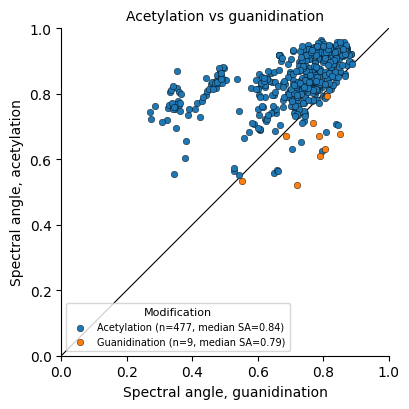

,panel,median_metric,n_PSMs,median,n_PSMs_PIC,n_PSMs_PRO,n_PSMs_PRO2
modification,,,,,,,
Acetylation,ED_Fig10b,spectral angle of the modification (0-1),477,0.843698,97,181,199
Guanidination,ED_Fig10b,spectral angle of the modification (0-1),9,0.786070,2,3,4


In [4]:
st = scatter(pts['b'], 'spectral_angle_guanidination', 'spectral_angle_acetylation', ['Acetylation', 'Guanidination'], 'Acetylation vs guanidination', 'Spectral angle, guanidination', 'Spectral angle, acetylation', 'ED_Fig10b')
st

## c — retention-time error, acetylation vs guanidination

PSMs of panel b with spectral angle guanidination ≥ spectral angle acetylation; abs(observed − predicted RT) / 70-min gradient for the guanidinated (x) and acetylated (y) candidate. Axis range 0–0.45; one guanidination point (x = 0.84) and one acetylation point (y = −0.01) lie outside it.

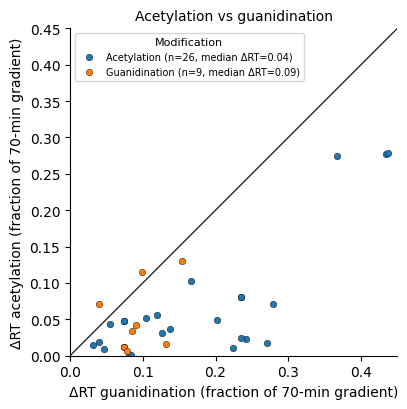

,panel,median_metric,n_PSMs,median,n_PSMs_PIC,n_PSMs_PRO,n_PSMs_PRO2
modification,,,,,,,
Acetylation,ED_Fig10c,abs delta RT of the modification (fraction of 70 min),26,0.040661,6,10,10
Guanidination,ED_Fig10c,abs delta RT of the modification (fraction of 70 min),9,0.090697,2,3,4


In [5]:
st = scatter(pts['c'], 'delta_RT_guanidination_fraction_of_70min', 'delta_RT_acetylation_fraction_of_70min', ['Acetylation', 'Guanidination'], 'Acetylation vs guanidination', 'ΔRT guanidination (fraction of 70-min gradient)', 'ΔRT acetylation (fraction of 70-min gradient)', 'ED_Fig10c', lim=(0, 0.45), stat='median ΔRT', legend_loc='upper left')
st

## d — propionylation vs diethylation / trimethylation

Points of the two comparisons (propionylation vs diethylation, propionylation vs trimethylation) in one plot; x = propionylated candidate, y = diethylated or trimethylated candidate.

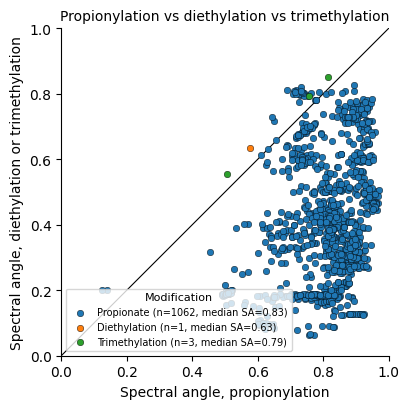

,panel,median_metric,n_PSMs,median,n_PSMs_PIC,n_PSMs_PRO,n_PSMs_PRO2
modification,,,,,,,
Propionate,ED_Fig10d,spectral angle of the modification (0-1),1062,0.826516,246,419,397
Diethylation,ED_Fig10d,spectral angle of the modification (0-1),1,0.633347,1,0,0
Trimethylation,ED_Fig10d,spectral angle of the modification (0-1),3,0.791887,1,2,0


In [6]:
st = scatter(pts['d'], 'spectral_angle_propionylation', 'spectral_angle_other', ['Propionate', 'Diethylation', 'Trimethylation'], 'Propionylation vs diethylation vs trimethylation', 'Spectral angle, propionylation', 'Spectral angle, diethylation or trimethylation', 'ED_Fig10d')
st

## e — N-pyruvic acid vs propionate-methyl (not identified as propionate-methyl in the closed search)

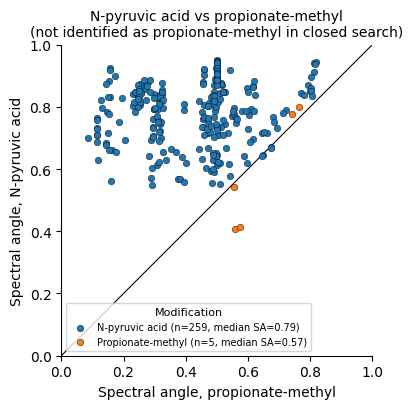

,panel,median_metric,n_PSMs,median,n_PSMs_PIC,n_PSMs_PRO,n_PSMs_PRO2
modification,,,,,,,
N-pyruvic acid,ED_Fig10e,spectral angle of the modification (0-1),259,0.791447,41,79,139
Propionate-methyl,ED_Fig10e,spectral angle of the modification (0-1),5,0.574048,0,2,3


In [7]:
st = scatter(pts['e'], 'spectral_angle_propionate_methyl', 'spectral_angle_N_pyruvic_acid', ['N-pyruvic acid', 'Propionate-methyl'], 'N-pyruvic acid vs propionate-methyl\n(not identified as propionate-methyl in closed search)', 'Spectral angle, propionate-methyl', 'Spectral angle, N-pyruvic acid', 'ED_Fig10e')
st

## f — N-pyruvic acid vs propionate-methyl (identified as propionate-methyl, K+70.04 Da, in the closed search)

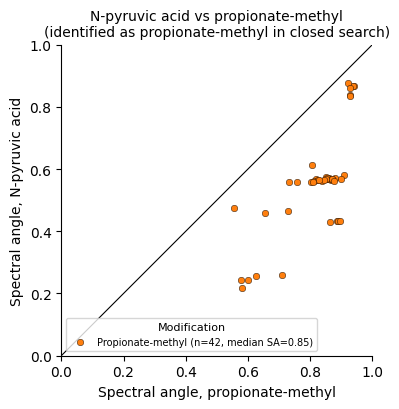

,panel,median_metric,n_PSMs,median,n_PSMs_PIC,n_PSMs_PRO,n_PSMs_PRO2
modification,,,,,,,
Propionate-methyl,ED_Fig10f,spectral angle of the modification (0-1),42,0.851994,7,18,17


In [8]:
st = scatter(pts['f'], 'spectral_angle_propionate_methyl', 'spectral_angle_N_pyruvic_acid', ['Propionate-methyl'], 'N-pyruvic acid vs propionate-methyl\n(identified as propionate-methyl in closed search)', 'Spectral angle, propionate-methyl', 'Spectral angle, N-pyruvic acid', 'ED_Fig10f')
st

## g — propionate-methyl & acetylation vs DST cross-linker & trimethylation

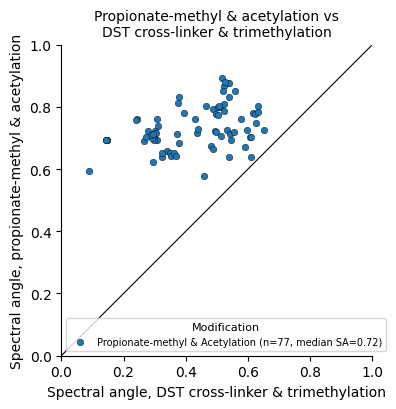

,panel,median_metric,n_PSMs,median,n_PSMs_PIC,n_PSMs_PRO,n_PSMs_PRO2
modification,,,,,,,
Propionate-methyl & Acetylation,ED_Fig10g,spectral angle of the modification (0-1),77,0.720526,16,0,61


In [9]:
st = scatter(pts['g'], 'spectral_angle_DST_trimethyl', 'spectral_angle_propionate_methyl_acetylation', ['Propionate-methyl & Acetylation'], 'Propionate-methyl & acetylation vs\nDST cross-linker & trimethylation', 'Spectral angle, DST cross-linker & trimethylation', 'Spectral angle, propionate-methyl & acetylation', 'ED_Fig10g')
st